In [1]:
%matplotlib inline

<div class="alert alert-block alert-warning">
This notebook has been adapted from <a href="https://github.com/courtois-neuromod/cneuromod-things/blob/main/datapaper/notebooks/fixation_compliance.ipynb">the notebook</a> used for <a href="https://www.nature.com/articles/s41597-026-06591-y">CNeuroMod-THINGS, a densely sampled fMRI dataset for visual neuroscience</a>
</div>

# Quality Checks: eye-tracking data

This notebook includes code and instructions to re-generate figures included in the Data Descriptor article for the CNeuroMod-emotion-videos dataset. These figures include:
- **Gaze variability**: distribution of gaze variability compared between fixation periods and stimuli presentation. Relationship between gaze variability and normative arousal scores.
- **Pupil detection confidence**: distribution of the pupil detection confidence for each participant
- **Gaze during stimuli**: dynamic representation of the gaze on videos

# 0 | Installation

### 0.1 | Install required Python libraries
To run this Notebook and re-create figures, you need to install the following Python libraries (e.g., inside a virtual environment). 


```shell
jupyter==1.0.0
numpy==2.4.1
pandas==3.0.0
matplotlib==3.10.8
seaborn==0.13.2
pybids==0.21.0
cmcrameri==1.8
```
<br/>

---

### 0.2 | Install the CNeuroMod-emotion-videos dataset

To generate figures, you need to download a few files from the CNeuroMod-emotion-videos dataset. 

Use the DataLad software (version > 1.0.0, https://www.datalad.org/) to clone the `cneuromod-emotion-videos` repository. 
DataLad is a versionning tool to manage large data structures organized in git repositories available for Linux, OSX and Windows. 

Note: the command below installs **symbolic links without downloading heavy files** onto your local machine.

```bash
datalad clone git@github.com:courtois-neuromod/cneuromod-emotion-videos.git
```
<br/>

---


### 0.3 | Pull the data files needed to generate figures

Before you can run this Notebook, you need to **download a few input files** onto your local machine. 

Inside the newly cloned `cneuromod-emotion-videos` repository, navigate to `cneuromod-emotion-videos/emotion-videos/emotion-videos.eyetrackprep`, which is a submodule inside the main repository.

```bash
cd cneuromod-emotion-videos/emotion-videos/emotion-videos.eyetrackprep
ls
```
<br/>

Use DataLad to download the `emotion-videos.eyetrackprep` submodule's symbolic links (**no large files will be pulled**).

```bash
datalad get *
ls
```
<br/>

Then, use DataLad again to download only the files you need onto your local machine.

```bash
datalad get sub-*/ses-*/func/*_desc-driftcorr_physio.tsv.gz
```
<br/>

Those files contain the drift corrected gaze. We will use them to look at the gaze variability in different context.


<br/>

We will do the same with the `cneuromod-emotion-videos/emotion-videos/cneuromod.emotion-videos.raw` submodule.

```bash
cd cneuromod-emotion-videos/emotion-videos/cneuromod.emotion-videos.raw
ls
```
<br/>

Use DataLad to download the `cneuromod.emotion-videos.raw` submodule's symbolic links (**no large files will be pulled**).

```bash
datalad get *
ls
```
<br/>

Then, use DataLad again to download only the files you need onto your local machine.

```bash
datalad get sub-*/ses-*/func/*_events.tsv
```
<br/>

Those files contain the onset and duration of the different events. We will use them to extract the periods of fixation and the stimuli presentation.

---
### 0.4 | Launch the Jupyter Notebook

Inside `cneuromod-emotion-videos`, navigate to the tutorial section, and open the current Jupyter Notebook (qc_gaze.ipynb)

```bash
cd cneuromod-emotion-videos/datapaper/notebooks
jupyter notebook
```
<br/>

---
# 1 | Import Python libraries

Run the code below to import Python libraries.

In [4]:
import warnings
warnings.filterwarnings('ignore')

import json
import os, glob
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import ptitprince as pt
import matplotlib.pyplot as plt
from cmcrameri import cm

import ffmpeg
import cv2
from datalad import api as dl
from moviepy import VideoFileClip
from scipy.interpolate import interp1d

from bids import BIDSLayout
from pingouin import mwu

Specify the runs to exclude for `sub-03` and `sub-05`.

In [51]:
EXCEPT_FILES = [
    {
        'subject': '03',
        'session': '001',
        'run': ['01', '02', '03']
    },
    {
        'subject': '05',
        'session': '002',
        'run': ['02', '04']
    }
]

---
# 2 | Gaze variability during fixation period vs stimuli presentation (Figure XX, XX panel)

**Fig. XX (XX)** features the distribution of gaze variability during the stimuli presentation compared to the fixation periods. Only gaze points above a pupil detection confidence threshold are included in the gaze variability calculation. Trials were included in the distribution only if the number of gaze was above a certain percentage of the trial duration multiplied by the sampling frequency (250Hz).

**Input files**: 
* gaze coordinates: `cneuromod-emotion-videos/emotion-videos/emotion-videos.eyetrackprep/sub-{sub_num}/ses-{ses-num}/func/sub-{sub_num}_ses-{ses-num}_task-emotion_run-{run-num}_recording-eye0_desc-driftcorr_physio.tsv.gz`
* quality thresholds: `cneuromod-emotion-videos/emotion-videos/emotion-videos.eyetrackprep/sub-{sub_num}/ses-{ses-num}/func/sub-{sub_num}_ses-{ses-num}_task-emotion_run-{run-num}_recording-eye0_desc-driftcorr_qcmetrics.json`
* events: `cneuromod-emotion-videos/emotion-videos/cneuromod.emotion-videos.raw/sub-{sub_num}/ses-{ses-num}/func/sub-{sub_num}_ses-{ses-num}_task-emotion_run-{run-num}_events.tsv`

### 2.1 | Set paths and variables

In [52]:
eyetrackprep_path = Path("../../cneuromod.emotion-videos/emotion-videos.eyetrackprep").resolve()
layout_eyetrackprep = BIDSLayout(eyetrackprep_path, is_derivative=True, validate=False)

raw_path = Path("../../cneuromod.emotion-videos/cneuromod.emotion-videos.raw").resolve()
layout_raw = BIDSLayout(raw_path, is_derivative=True, validate=False)

output_path = Path('../figures/eyetrack').resolve()

### 2.2 | Run the code below to generate Fig. XX (XX)

Some parameters can be changed in the cell below to obtain the distributions for specific subjects and different thresholds:

- `subjects`: list of str (subject id). Currently, all subjects present in `layout_eyetrackprep` are considered. If you want to plot the distribution for a given subject, for example sub-03, you can change the first line to: `subjects = ['03']`.
- `delay_onset_*`: float defining the delay between the onset of an event ('fix' or 'stim') and the start of the segment used for gaze variability extraction (in seconds). Currently the value is set to `0.7` for the `delay_onset_fix`, which means that the first 0.7 seconds of gaze data for the events will be ignored. This value is coherent with [`eyetrackprep`](https://github.com/courtois-neuromod/eyetrackprep) drift correction procedure for the fixations. For the `delay_onset_stim` the value is set to `0.0`, which mean that the gaze for the entire stimuli will be considered. It is important to note that the duration of fixations was 1.5 seconds and the duration of the stimuli varied between 1 and 20 seconds.
- `gaze_ratio_*`: float between 0.0 and 1.0 defining the minimum proportion of gaze points with pupil detection confidence > 90% required for an event ('fix' or 'stim') to be included in the distributions. Currently, the value for `gaze_ratio_fix` is set to `None`. In that case, the value is retrieved from the `MinProportionGazePerFix` field in the `*qcmetrics.json` files. The value of `gaze_ratio_stim` is set to `None`, which means that the code will consider the same value as `gaze_ratio_fix`.

In [53]:
subjects = layout_eyetrackprep.get_subject()

delay_onset_fix, gaze_ratio_fix = 0.7, None
delay_onset_stim, gaze_ratio_stim = 0.0, None


sf = 250 # sampling frequency (in Hz)
df_gaze = pd.DataFrame(columns=['x_stdev', 'y_stdev', 'trial_type', 'subject', 'session', 'run', 'stim_file', 'confidence'])
df_gaze_run = pd.DataFrame(columns=['x_stdev', 'y_stdev', 'trial_type', 'subject', 'session', 'run'])


for i, sub in enumerate(subjects):
    sessions = layout_eyetrackprep.get_session(subject=sub)
    
    for ses in sessions:
        runs = layout_eyetrackprep.get_run(subject=sub, session=ses)
        
        for run in runs:
            files = layout_eyetrackprep.get(subject=sub, session=ses, run=run, desc='driftcorr', suffix='physio', extension='tsv.gz')
            
            for file in files:
                print(file.filename)
                entities = file.get_entities()
                metadata = file.get_metadata()
                df_tmp_fixation = pd.DataFrame(columns=['x_coordinate', 'y_coordinate', 'trial_type', 'subject', 'session', 'run'])
                df_tmp_stimulus = pd.DataFrame(columns=['x_coordinate', 'y_coordinate', 'trial_type', 'subject', 'session', 'run'])
                
                except_f = False
                for except_file in EXCEPT_FILES:
                    if except_file['subject'] == sub:
                        if except_file['session'] == ses:
                            if str(run) in except_file['run']:
                                except_f = True
                                
                if not except_f:
                    # Retrieve gaze timeseries
                    gaze = file.get_df()
                    # ---
                    # Retrieve gaze qc metrics
                    if gaze_ratio_fix is None:
                        qc = layout_eyetrackprep.get(subject=entities['subject'], session=entities['session'], run=entities['run'], desc='driftcorr', suffix='qcmetrics', extension='json')

                        if len(qc) != 1:
                            raise IOError(f'Problem with qcmetrics files associated with {file.filename}: {len(qc)}')

                        print(f'Retrieve qc file: {qc[0].filename}')
                        with open(qc[0].path) as f:
                            qc = json.load(f)
                            f.close
                        gaze_ratio_fix = qc['MinProportionGazePerFix']['Value']
                    
                    if gaze_ratio_stim is None:
                        gaze_ratio_stim = gaze_ratio_fix

                    # ---
                    # Retrieve events files
                    events = layout_raw.get(subject=entities['subject'], session=entities['session'], run=entities['run'], suffix='events', extension='tsv')

                    if len(events) != 1:
                        raise IOError(f'Problem with events files associated with {file.filename}: {len(events)}')

                    print(f'Retrieve events file: {events[0].filename}')
                    events = events[0].get_df()

                    # Keep gaze points above `PupilConfidenceThreshold`
                    gaze_qced = gaze[gaze['confidence']>0.9] #qc['PupilConfidenceThreshold']['Value']]

                    # Segment `gaze_qced` into events (i.e., fixation periods and stimuli)
                    for i_e, e in events.iterrows():
                        # Get onset and offset of fixation period
                        onset_fixation = e['onset_fixation_flip'] + delay_onset_fix
                        offset_fixation = e['onset_video_flip']

                        # Retrieve gaze points related to the fixation
                        gaze_fixation = gaze_qced[(gaze_qced['timestamp']>=onset_fixation)&(gaze_qced['timestamp']<=offset_fixation)]

                        # Keep fixation only if number of gaze above threshold
                        if len(gaze_fixation) > int(gaze_ratio_fix * (offset_fixation-onset_fixation) * sf):
                            df_gaze = pd.concat([df_gaze, pd.DataFrame({'x_stdev': [gaze_fixation['x_coordinate'].std()], 'y_stdev': [gaze_fixation['y_coordinate'].std()],'trial_type': ['fixation'], 'subject': [f'sub-{sub}'], 'session': [f"{entities['session']}"], 'run': [f"{entities['run']}"], 'stim_file': [e['stim_file']], 'confidence': [gaze_fixation['confidence'].median()]})])
                        df_tmp_fixation = pd.concat([df_tmp_fixation, pd.DataFrame({'x_coordinate': gaze_fixation['driftcorr_x_coordinate'], 'y_coordinate': gaze_fixation['driftcorr_y_coordinate']})])

                        # Get onset and offset of the stimulus presentation
                        onset_stimulus = e['onset_video_flip'] + delay_onset_stim
                        offset_stimulus = e['onset_video_flip'] + e['duration']

                        # Retrieve gaze points related to the stimulus
                        gaze_stimulus = gaze_qced[(gaze_qced['timestamp']>=onset_stimulus)&(gaze_qced['timestamp']<=offset_stimulus)]
                        # Keep stimulus only if number of gaze above threshold
                        if len(gaze_stimulus) >  int(gaze_ratio_stim * (offset_stimulus-onset_stimulus) * sf):
                            df_gaze = pd.concat([df_gaze, pd.DataFrame({'x_stdev': [gaze_stimulus['x_coordinate'].std()], 'y_stdev': [gaze_stimulus['y_coordinate'].std()],'trial_type': ['stimulus'], 'subject': [f'sub-{sub}'], 'session': [f"{entities['session']}"], 'run':[f"{entities['run']}"], 'stim_file': [e['stim_file']], 'confidence': [gaze_stimulus['confidence'].median()]})])
                        df_tmp_stimulus = pd.concat([df_tmp_stimulus, pd.DataFrame({'x_coordinate': gaze_stimulus['driftcorr_x_coordinate'], 'y_coordinate': gaze_stimulus['driftcorr_y_coordinate']})])
            
            # Add fixation periods
            df_gaze_run = pd.concat([df_gaze_run, pd.DataFrame({'x_stdev': [df_tmp_fixation['x_coordinate'].std()], 'y_stdev': [df_tmp_fixation['y_coordinate'].std()], 'trial_type': ['fixation'], 'subject': sub, 'session': ses, 'run': run})])
            # add stimulus presentation periods
            df_gaze_run = pd.concat([df_gaze_run, pd.DataFrame({'x_stdev': [df_tmp_stimulus['x_coordinate'].std()], 'y_stdev': [df_tmp_stimulus['y_coordinate'].std()], 'trial_type': ['stimulus'], 'subject': sub, 'session': ses, 'run': run})])
                                                     
df_gaze = df_gaze.reset_index(drop=True)
df_gaze_run = df_gaze_run.reset_index(drop=True)

sub-01_ses-001_task-emotion_run-01_recording-eye0_desc-driftcorr_physio.tsv.gz
Retrieve qc file: sub-01_ses-001_task-emotion_run-01_recording-eye0_desc-driftcorr_qcmetrics.json
Retrieve events file: sub-01_ses-001_task-emotion_run-01_events.tsv
sub-01_ses-001_task-emotion_run-02_recording-eye0_desc-driftcorr_physio.tsv.gz
Retrieve events file: sub-01_ses-001_task-emotion_run-02_events.tsv
sub-01_ses-001_task-emotion_run-03_recording-eye0_desc-driftcorr_physio.tsv.gz
Retrieve events file: sub-01_ses-001_task-emotion_run-03_events.tsv
sub-01_ses-001_task-emotion_run-04_recording-eye0_desc-driftcorr_physio.tsv.gz
Retrieve events file: sub-01_ses-001_task-emotion_run-04_events.tsv
sub-01_ses-001_task-emotion_run-05_recording-eye0_desc-driftcorr_physio.tsv.gz
Retrieve events file: sub-01_ses-001_task-emotion_run-05_events.tsv
sub-01_ses-001_task-emotion_run-06_recording-eye0_desc-driftcorr_physio.tsv.gz
Retrieve events file: sub-01_ses-001_task-emotion_run-06_events.tsv
sub-01_ses-002_task-

Retrieve events file: sub-02_ses-005_task-emotion_run-05_events.tsv
sub-02_ses-005_task-emotion_run-06_recording-eye0_desc-driftcorr_physio.tsv.gz
Retrieve events file: sub-02_ses-005_task-emotion_run-06_events.tsv
sub-02_ses-006_task-emotion_run-01_recording-eye0_desc-driftcorr_physio.tsv.gz
Retrieve events file: sub-02_ses-006_task-emotion_run-01_events.tsv
sub-02_ses-006_task-emotion_run-02_recording-eye0_desc-driftcorr_physio.tsv.gz
Retrieve events file: sub-02_ses-006_task-emotion_run-02_events.tsv
sub-02_ses-006_task-emotion_run-03_recording-eye0_desc-driftcorr_physio.tsv.gz
Retrieve events file: sub-02_ses-006_task-emotion_run-03_events.tsv
sub-02_ses-006_task-emotion_run-04_recording-eye0_desc-driftcorr_physio.tsv.gz
Retrieve events file: sub-02_ses-006_task-emotion_run-04_events.tsv
sub-02_ses-006_task-emotion_run-05_recording-eye0_desc-driftcorr_physio.tsv.gz
Retrieve events file: sub-02_ses-006_task-emotion_run-05_events.tsv
sub-02_ses-006_task-emotion_run-06_recording-eye0_

sub-05_ses-002_task-emotion_run-02_recording-eye0_desc-driftcorr_physio.tsv.gz
sub-05_ses-002_task-emotion_run-03_recording-eye0_desc-driftcorr_physio.tsv.gz
Retrieve events file: sub-05_ses-002_task-emotion_run-03_events.tsv
sub-05_ses-002_task-emotion_run-04_recording-eye0_desc-driftcorr_physio.tsv.gz
sub-05_ses-003_task-emotion_run-01_recording-eye0_desc-driftcorr_physio.tsv.gz
Retrieve events file: sub-05_ses-003_task-emotion_run-01_events.tsv
sub-05_ses-003_task-emotion_run-02_recording-eye0_desc-driftcorr_physio.tsv.gz
Retrieve events file: sub-05_ses-003_task-emotion_run-02_events.tsv
sub-05_ses-003_task-emotion_run-03_recording-eye0_desc-driftcorr_physio.tsv.gz
Retrieve events file: sub-05_ses-003_task-emotion_run-03_events.tsv
sub-05_ses-004_task-emotion_run-01_recording-eye0_desc-driftcorr_physio.tsv.gz
Retrieve events file: sub-05_ses-004_task-emotion_run-01_events.tsv
sub-05_ses-004_task-emotion_run-02_recording-eye0_desc-driftcorr_physio.tsv.gz
Retrieve events file: sub-05

In [54]:
results = pd.DataFrame()

for sub in df_gaze['subject'].unique():
    df_test = df_gaze[df_gaze['subject']==sub]
    df_test_inscreen_x = df_test[df_test['x_stdev']<=1]
    df_test_inscreen_y = df_test[df_test['y_stdev']<=1]
    
    df_res_x = mwu(df_test_inscreen_x[df_test_inscreen_x['trial_type']=='stimulus']['x_stdev'].dropna().values.astype(float), df_test_inscreen_x[df_test_inscreen_x['trial_type']=='fixation']['x_stdev'].dropna().values.astype(float), alternative='two-sided')
    df_res_x['subject'] = sub
    df_res_x['axis'] = 'x'
    df_res_y = mwu(df_test_inscreen_y[df_test_inscreen_y['trial_type']=='stimulus']['y_stdev'].dropna().values.astype(float), df_test_inscreen_y[df_test_inscreen_y['trial_type']=='fixation']['y_stdev'].dropna().values.astype(float), alternative='two-sided')
    df_res_y['subject'] = sub
    df_res_y['axis'] = 'y'
    
    results = pd.concat([results, df_res_x, df_res_y])

print(results)

         U_val alternative          p_val       RBC      CLES subject axis
MWU  2141706.0   two-sided   0.000000e+00  0.935496  0.967748  sub-01    x
MWU  2106192.0   two-sided   0.000000e+00  0.904726  0.952363  sub-01    y
MWU  2723471.0   two-sided   0.000000e+00  0.835950  0.917975  sub-02    x
MWU  2674713.0   two-sided   0.000000e+00  0.803082  0.901541  sub-02    y
MWU  1620855.0   two-sided   3.717111e-78  0.391178  0.695589  sub-03    x
MWU  1738590.0   two-sided  1.257308e-122  0.492230  0.746115  sub-03    y
MWU  1075117.0   two-sided  3.762215e-122  0.560227  0.780113  sub-05    x
MWU  1059245.0   two-sided  5.727771e-113  0.538516  0.769258  sub-05    y
MWU  2217528.0   two-sided   0.000000e+00  0.878291  0.939145  sub-06    x
MWU  2186048.0   two-sided   0.000000e+00  0.852885  0.926442  sub-06    y


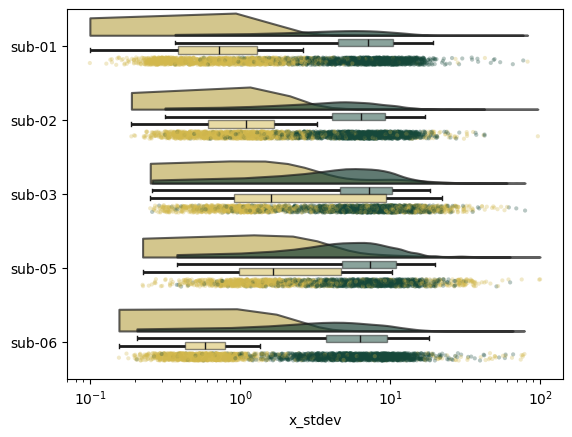

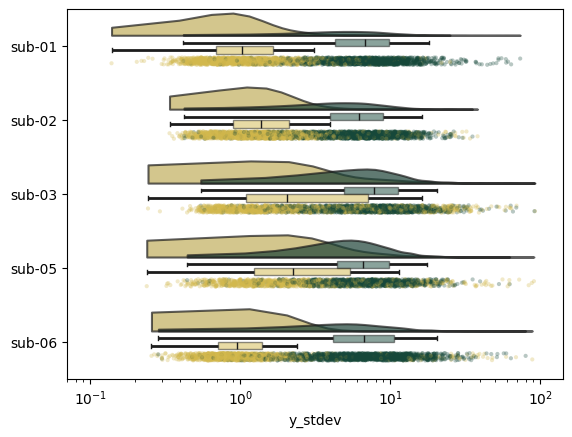

In [56]:
# Set seed to reproduce the stripplot jitter
np.random.seed(42)
convert_to_percent = True

var_axis = ['x_stdev', 'y_stdev']

for v in var_axis:
    dy='subject'; dx=v; ort='h'; hue='trial_type'
    # Only keep gaze in screen
    df_gaze_inscreen = df_gaze[df_gaze[dx]<=1]

    # Convert proportion on the screen in percentage to have
    # the x axis start at 0
    if convert_to_percent:
        df_gaze_inscreen[dx] = df_gaze_inscreen[dx] * 100
        suffix = 'percent'
        xmin, xmax = 0.07, 142
    else:
        suffix = 'proportion'
        xmin, xmax = 0.0007, 1.42
    
    # Define colors
    cmap=sns.color_palette(cm.bamako.resampled(7).colors)
    cmap=sns.color_palette(np.array([cmap[1], cmap[5]]))
    
    plt.figure(figsize=( 6.4, 4.8))

    ax = pt.half_violinplot(x = dx, y = dy, hue=hue, data = df_gaze_inscreen, bw = .2, cut = 0.,
                          scale = "area", width = .6, inner = None, orient = ort, palette=cmap, alpha=0.7)

    ax = pt.stripplot(
        x=dx,
        y=dy,
        hue=hue,
        data=df_gaze_inscreen,
        edgecolor="white",
        size=2,
        alpha=0.30,
        s=3,
        jitter=0.05,
        zorder=20,
        orient=ort,
        move=0.2,
        palette=cmap
    )

    ax=sns.boxplot(x = dx, y = dy, hue=hue, data = df_gaze_inscreen, width = .20, zorder = 10, 
                   showcaps = True, showfliers=False, boxprops={'alpha': 0.5},
                   whiskerprops = {'linewidth':2, "zorder":10}, saturation = 1, orient = ort, palette=cmap)

    ax.legend_.remove()
    ax.set_xscale("log")
    ax.set_xlim(xmin=xmin, xmax=xmax)

    for collection in ax.collections:
        collection.set_rasterized(True)

    plt.ylabel('')

    output_path.mkdir(parents=True, exist_ok=True)
    plt.savefig(os.path.join(output_path, f'gaze_variability_delayFix-{str(delay_onset_fix).replace(".", "")}_gazeRatioFix-{str(gaze_ratio_fix).replace(".", "")}_delayStim-{str(delay_onset_stim).replace(".", "")}_gazeRatioStim-{str(gaze_ratio_stim).replace(".","")}_{dx}_transform-logscale_{suffix}.svg'), dpi=600, transparent=True)

---
# 3 | Gaze on stimuli videos

The generated videos show the gaze pattern on a given stimulus. The gaze of the different subjects is represented by different colors.

**Input files**: 
* drift corrected gaze: `cneuromod-emotion-videos/emotion-videos/emotion-videos.eyetrackprep/sub-{sub_num}/ses-{ses-num}/func/sub-{sub_num}_ses-{ses-num}_task-emotion_run-{run-num}_recording-eye0_desc-driftcorr_physio.tsv.gz`
* events: `cneuromod-emotion-videos/emotion-videos/cneuromod.emotion-videos.raw/sub-{sub_num}/ses-{ses-num}/func/sub-{sub_num}_ses-{ses-num}_task-emotion_run-{run-num}_events.tsv`

### 3.1 | Set paths and variables

In [57]:
eyetrackprep_path = Path("../../emotion-videos.eyetrackprep").resolve() 
layout_eyetrackprep = BIDSLayout(eyetrackprep_path, is_derivative=True, validate=False)

raw_path = Path("../../cneuromod.emotion-videos.raw").resolve()
layout_raw = BIDSLayout(raw_path, is_derivative=True, validate=False)

stimuli_path = Path("../../emotions.stimuli").resolve()

cache_path = Path('../cache').resolve()
cache_path.mkdir(parents=True, exist_ok=True)
output_path = Path('../figures/eyetrack').resolve()
output_path.mkdir(parents=True, exist_ok=True)

### 3.2 | Define utils functions


In [83]:
subject_colors = {
    "sub-01": (0, 153, 0),      # green
    "sub-02": (255, 128, 0),    # orange
    "sub-03": (0, 128, 255),    # blue
    "sub-05": (76, 0, 153),     # purple
    "sub-06": (153, 0, 76),     # red-pink
}

FULL_SCREEN_SIZE = (1280, 1024)  # pix
SCALING_EMOTION_VIDEOS = 900  # pix

def parse_file_name(
    file_name: str,
)-> dict:
    """."""
    file_bits = file_name.split("_")
    
    fb_dict = {}
    for fb in file_bits:
        fb_bits = fb.split("-")
        if len(fb_bits) == 2:
            if fb_bits[0].isdigit():
                fb_dict["fnum"] = fb
            else:
                fb_dict[fb_bits[0]] = fb_bits[1]
    return fb_dict


def add_sesrun_2ev(f_path, path_raw): 
    eb = parse_file_name(Path(f_path).name) 

    if not Path(f_path).exists():
        dl.get(path=f_path, dataset=path_raw, jobs="auto")
    
    df = pd.read_csv(f_path, sep='\t')
        
    df.insert(loc=0, column="subject_id", value=str(eb["sub"]), allow_duplicates=True)
    df.insert(loc=1, column="session_id", value=str(eb["ses"]), allow_duplicates=True)
    df.insert(loc=2, column="run_id", value=str(eb["run"]), allow_duplicates=True)
    
    return df    


def concat_events(subjects, layout_raw):
    for sub in subjects:
        sub_evpath = f"{cache_path}/sub-{sub}_task-emotionvideos_desc-concat_events.tsv"
        
        ev_list = layout_raw.get(subject=sub, suffix='events', extension='tsv')
        for ev in ev_list:
            entities = ev.get_entities()
            for except_file in EXCEPT_FILES:
                if except_file['subject'] == sub:
                    if except_file['session'] == entities['session']:
                        if str(entities['run']) in except_file['run']:
                            ev_list.remove(ev)
        
        ev_df = pd.concat([add_sesrun_2ev(f, layout_raw.root) for f in ev_list], ignore_index=True)

        ev_df.to_csv(sub_evpath, sep="\t", header=True, index=False)
    
    return ev_df


def get_video_specs(
    video_path: str,
)-> dict:
    """
    use ffmpeg to extract video specs
    """
    probe = ffmpeg.probe(video_path)
    video_specs = next(
        (stream for stream in probe['streams'] if stream['codec_type'] == 'video'
    ), None)
    
    width = int(video_specs['width'])
    height = int(video_specs['height'])
    
    # FPS is usually stored as a fraction like "60000/1001" or "30/1"
    fps_eval = video_specs['avg_frame_rate'].split('/')
    fps = float(fps_eval[0]) / float(fps_eval[1])
    
    # nb_frames is the most accurate frame count available in the header
    # Fallback to duration * fps if nb_frames is missing
    duration = float(video_specs.get('duration', probe['format']['duration']))
    nb_frames = int(video_specs.get('nb_frames', round(duration * fps)))
    
    return {
        "width": width,
        "height": height,
        "fps": fps,
        "duration": duration,
        "nb_frames": nb_frames,
    }


def norm2pix(
    video_specs: dict,
    df_trial: pd.DataFrame,
) -> tuple[np.ndarray, np.ndarray]:
    """
    Function converts gaze from normalized to pixel space
    Cartesian coordinates x and y as percent of screen -> coordinates h, w on image frame (array))
    """
    video_width = video_specs['width']
    video_height = video_specs['height']

    x_pix = df_trial['x_coord'].to_numpy() * FULL_SCREEN_SIZE[0]
    y_pix = (1.0 - df_trial['y_coord'].to_numpy()) * FULL_SCREEN_SIZE[1]   

    if video_width > video_height:
        """
        video full width is projected onto screen's central 900 pixels 
        (full width is 1280, with 190 pixels of padding on either side).
        Gaze position is clipped to remain on the movie frame
        """
        x_pix = np.floor((x_pix - 190) * (video_width/SCALING_EMOTION_VIDEOS)).astype(int)
        x_pix = np.clip(x_pix, 0, int(video_width-1))

        """
        height is scaled proortionally to width
        """
        projected_height = (video_height / video_width) * SCALING_EMOTION_VIDEOS
        edge_y = int((FULL_SCREEN_SIZE[1] - projected_height)/2)
        y_pix = np.floor((y_pix - edge_y) * (video_height/projected_height)).astype(int)
        y_pix = np.clip(y_pix, 0, int(video_height-1))

    else:
        """
        video full height is projected onto screen's central 900 pixels
        (full height is 1024, with 62 pixels of padding on either side).
        Gaze position is clipped to remain on the movie frame
        """
        y_pix = np.floor((y_pix - 62) * (video_height/SCALING_EMOTION_VIDEOS)).astype(int)
        y_pix = np.clip(y_pix, 0, int(video_height-1))

        """
        width is scaled proportionally to height
        """
        projected_width = (video_width / video_height) * SCALING_EMOTION_VIDEOS
        edge_x = int((FULL_SCREEN_SIZE[0] - projected_width)/2)
        x_pix = np.floor((x_pix - edge_x) * (video_width/projected_width)).astype(int)
        x_pix = np.clip(x_pix, 0, int(video_width-1))

    df_trial.insert(loc=1, column="x_pix", value=x_pix, allow_duplicates=True)
    df_trial.insert(loc=2, column="y_pix", value=y_pix, allow_duplicates=True)

    return df_trial


def drawgaze(clip,fx,fy,r_zone,rgb=(255,0,0)):
    """
    Adapted from: https://zulko.github.io/moviepy/examples/headblur.html
    Returns a filter that will add a moving circle that corresponds to the gaze mapped onto
    the frames. The position of the circle at time t isdefined by (fx(t), fy(t)), 
    and the radius of the circle by ``r_zone``.
    Requires OpenCV for the circling. Automatically deals with the case where part 
    of the image goes offscreen.
    """    
    
    def gaze2frame(get_frame,t):
        im_orig = get_frame(t)
        im = np.copy(im_orig)

        try:
            x,y = int(fx(t)),int(fy(t))        
        except ValueError:
            # If t is outside interpolation range, return original frame
            return im

        h,w,d = im.shape
        x1,x2 = max(0,x-r_zone),min(x+r_zone,w)
        y1,y2 = max(0,y-r_zone),min(y+r_zone,h)
        region_size = y2-y1,x2-x1

        orig = im[y1:y2, x1:x2]
        circled = cv2.circle(orig, (r_zone, r_zone), r_zone, rgb, -1,
                             lineType=cv2.LINE_AA)

        im[y1:y2, x1:x2] = circled
        
        return im

    return clip.transform(gaze2frame)   

### 3.3 | Run the code below to generate the videos

Some parameters can be changed in the cell below to obtain the gaze pattern for different stimuli and different subjects:

- `video_num`:  str indicating the stimuli identifier.
- `gaze_sampling`: int indicating the gaze downsampling factor. E.g., at sampling=5, the gaze is sampled every 5 frames. Sampling=1 means no downsampling (250 fps). Gaze is acquired at 250 fps.
- `conf_thresh`: float between 0.0 and 1.0 indicating the pupil detection confidence threshold. Gaze points with confidence inferior to `conf_thresh` are not displayed.
- `subjects`: list of str (subject id). Currently, all subjects present in `layout_eyetrackprep` are considered. If you want to plot the distribution for a given subject, for example sub-03, you can change the first line to: `subjects = ['03']`.
- `identify_sub`: bool indicating whether or not to use different colors to differenciate the participants' gaze. If False, all the gaze points are the same color.
- `drift_corr`: bool indicating if the drift corrected gaze coordinates should be used. If `False`, the raw gaze coordinates are used.

In [127]:
video_num = "0004.mp4"
gaze_sampling = 1 
conf_thresh = 0.9

identify_sub = True
drift_corr = False

subjects = layout_eyetrackprep.get_subjects()

# Retrieve events
events = concat_events(subjects, layout_raw)

# Retrieve stimuli
video_path = os.path.join(stimuli_path, 'clips_repeated', video_num)
if not Path(video_path).exists():
    dl.get(path=video_path, dataset=videos_path, jobs="auto")

video_specs = get_video_specs(video_path)

<div class="alert alert-block alert-danger">
<b>TW:</b> The stimuli were selected to cover a broad range of emotional states. The content of some stimuli may include violence, mutilation, injury, scary elements. The cell below prints the category that was the most reported/experienced among participants from a different dataset for the stimulus selected in the cell above (`video_num`).
</div>

In [128]:
categories = ['admiration', 'adoration', 'aesthetic appreciation',
       'amusement', 'anger', 'anxiety', 'awe', 'awkwardness', 'boredom',
       'calmness', 'confusion', 'contempt', 'craving', 'disappointment',
       'disgust', 'empathic pain', 'entrancement', 'envy', 'excitement',
       'fear', 'guilt', 'horror', 'interest', 'joy', 'nostalgia', 'pride',
       'relief', 'romance', 'sadness', 'satisfaction', 'sexual desire',
       'surprise', 'sympathy', 'triumph']

dimensions = ['approach', 'arousal', 'attention',
       'certainty', 'commitment', 'control', 'dominance', 'effort', 'fairness',
       'identity', 'obstruction', 'safety', 'upswing', 'valence']

annotation = events[events['stim_file']==video_num]

print(f"Category with the highest score for {video_num}:\n... {annotation[categories].idxmax(axis=1).values[0]}")
print(f"Averaged valence score for {video_num} (on a 9-point likert scale):\n... {annotation['valence'].values[0]}")
print(f"Averaged arousal score for {video_num} (on a 9-point likert scale):\n... {annotation['arousal'].values[0]}")

Category with the highest score for 0605.mp4:
... joy
Averaged valence score for 0605.mp4 (on a 9-point likert scale):
... 7.0
Averaged arousal score for 0605.mp4 (on a 9-point likert scale):
... 5.7778


In [129]:
gaze_interpol = {}

for sub in subjects:
    
    sub_evpath = f"{cache_path}/sub-{sub}_task-emotionvideos_desc-concat_events.tsv"
    sub_ev = pd.read_csv(sub_evpath, sep="\t", dtype={'subject_id': str, 'session_id': str, 'run_id': str})
    
    if video_num in np.unique(sub_ev['stim_file']):
        sub_vtrial = sub_ev[sub_ev['stim_file'] == video_num]
        #  Sanity check: there should be one trial matching each video for each subject
        assert sub_vtrial.shape[0] == 1

        # session, run, onset and onset for the trial matching the specified video        
        ses = sub_vtrial.iloc[0]['session_id']
        run = sub_vtrial.iloc[0]['run_id']
        trial_onset = sub_vtrial.iloc[0]['onset_video_flip']
        trial_offset = trial_onset + sub_vtrial.iloc[0]['total_duration']

        # Retrieve corresponding gaze position
        gz_path = layout_eyetrackprep.get(subject=sub, session=ses, run=run, desc='driftcorr', suffix='physio', extension='tsv.gz')
        
        if not Path(gz_path[0]).exists():
            if Path(gz_path[0]).is_symlink():
                dl.get(path=gz_path[0], dataset=layout_eyetrackprep.root, jobs="auto")
            else:        
                continue
                
        df_gz = gz_path[0].get_df()[::gaze_sampling]
        if drift_corr:
            x_coord, y_coord = 'driftcorr_x_coordinate', 'driftcorr_y_coordinate'
        else:
            x_coord, y_coord = 'x_coordinate', 'y_coordinate'
        
        df_gz = df_gz[["timestamp", x_coord, y_coord, "confidence"]]
        df_gz = df_gz.rename(columns={x_coord: "x_coord", y_coord: "y_coord"})
        
        # Only keeps gaze with pupil detection confidence above `conf_thresh`
        df_gz = df_gz[df_gz["confidence"].to_numpy() > conf_thresh] 

        df_trial = df_gz[np.logical_and(
            df_gz['timestamp'].to_numpy() > trial_onset - 0.1, 
            df_gz['timestamp'].to_numpy() < trial_offset + 0.1 
        )].reset_index(drop=True)

        if df_trial.shape[0] == 0:
            continue
        else:
            # re-align gaze timestamps with trial (rather than run) onset 
            df_trial.insert(loc=0, column="trial_timestamp", value=df_trial['timestamp'].to_numpy() - trial_onset)

            # convert trial's gaze position from normalized (screen proportion) to pixels, based on video dim and projection to screen
            df_trial = norm2pix(video_specs, df_trial)

            """
            Create interpolation function in x and y (per trial)
            https://docs.scipy.org/doc/scipy/reference/reference/generated/scipy.interpolate.interp1d.html#scipy.interpolate.interp1d
            kind: 'linear’, ‘nearest’, ‘nearest-up’, ‘zero’, ‘slinear’, ‘quadratic’, ‘cubic’, ‘previous’, or ‘next’.
            """
            gaze_times = df_trial['trial_timestamp'].to_numpy()

            gaze_interpol[f"sub-{sub}"] = {
                "f_xcoord": interp1d(gaze_times, df_trial['x_pix'].to_numpy(), kind='linear'),
                "f_ycoord": interp1d(gaze_times, df_trial['y_pix'].to_numpy(), kind='linear'),                          
            }
                

# Sanity check: is there at least one subject with gaze data for that trial?
print(gaze_interpol.keys())

dict_keys(['sub-01', 'sub-02', 'sub-03', 'sub-06'])


In [130]:
# load video with moviepy
clip = VideoFileClip(video_path)

"""
Draw gaze points on each frame and write video file
"""
gaze_radius_in_pix = int(video_specs['width']*0.015)  # scale gaze radius to 5% of video frame width

for sub, f_interp in gaze_interpol.items():
    rgb = subject_colors[sub] if identify_sub else (255, 0, 0)
    clip_gaze = drawgaze(clip, f_interp["f_xcoord"], f_interp["f_ycoord"], gaze_radius_in_pix, rgb)
    clip = clip_gaze

if drift_corr:
    dc_desc='Corr'
else:
    dc_desc='Uncorr'
video_out_name = f"{output_path}/mv-{video_num.split('.')[0]}_desc-wGaze{dc_desc}.mp4"
clip.write_videofile(video_out_name)  

MoviePy - Building video /home/user/Documents/emotion-videos.datapaper/figures/eyetrack/mv-0605_desc-wGazeUncorr.mp4.
MoviePy - Writing video /home/user/Documents/emotion-videos.datapaper/figures/eyetrack/mv-0605_desc-wGazeUncorr.mp4



MoviePy - Done !
MoviePy - video ready /home/user/Documents/emotion-videos.datapaper/figures/eyetrack/mv-0605_desc-wGazeUncorr.mp4


---
# 4 | Pupil detection confidence distribution during stimuli presentation (Figure XX, XX panel)

**Fig. XX (XX)** features the distribution of pupil detection confidence during the stimuli presentation. The pupil algorithm detection confidence values were outputted by the eye-tracking acquisition software (Pupil Capture version 3.2.763). A value of 0 would mean that the pupil could not be detected and a value of 1 represents a very high certainty of pupil detection.

**Input files**: 
* pupil detection confidence: `cneuromod-emotion-videos/emotion-videos/emotion-videos.eyetrackprep/sub-{sub_num}/ses-{ses-num}/func/sub-{sub_num}_ses-{ses-num}_task-emotion_run-{run-num}_recording-eye0_desc-driftcorr_physio.tsv.gz`
* events: `cneuromod-emotion-videos/emotion-videos/cneuromod.emotion-videos.raw/sub-{sub_num}/ses-{ses-num}/func/sub-{sub_num}_ses-{ses-num}_task-emotion_run-{run-num}_events.tsv`

### 4.1 | Set paths and variables

In [40]:
eyetrackprep_path = Path("../../emotion-videos.eyetrackprep").resolve()
layout_eyetrackprep = BIDSLayout(eyetrackprep_path, is_derivative=True, validate=False)

raw_path = Path("../../cneuromod.emotion-videos.raw").resolve()
layout_raw = BIDSLayout(raw_path, is_derivative=True, validate=False)

output_path = Path('../figures/eyetrack').resolve()

### 4.2 | Run the code below to generate Fig. XX (XX)

Some parameters can be changed in the cell below to obtain the distributions for specific subjects:

- `subjects`: list of str (subject id). Currently, all subjects present in `layout_eyetrackprep` are considered. If you want to plot the distribution for a given subject, for example sub-03, you can change the first line to: `subjects = ['03']`.

In [30]:
subjects = layout_eyetrackprep.get_subject()

sf = 250 # sampling frequency (in Hz)
df_gaze = pd.DataFrame(columns=['subject', 'session', 'run', 'stim_file', 'confidence'])

for i, sub in enumerate(subjects):
    sessions = layout_eyetrackprep.get_session(subject=sub)
    
    for ses in sessions:
        runs = layout_eyetrackprep.get_run(subject=sub, session=ses)
        
        for run in runs:
            files = layout_eyetrackprep.get(subject=sub, session=ses, run=run, desc='driftcorr', suffix='physio', extension='tsv.gz')
            
            for file in files:
                print(file.filename)
                entities = file.get_entities()
                metadata = file.get_metadata()
                
                except_f = False
                for except_file in EXCEPT_FILES:
                    if except_file['subject'] == sub:
                        if except_file['session'] == ses:
                            if str(run) in except_file['run']:
                                except_f = True
                                
                if not except_f:
                    # Retrieve gaze timeseries
                    gaze = file.get_df()

                    # ---
                    # Retrieve events files
                    events = layout_raw.get(subject=entities['subject'], session=entities['session'], run=entities['run'], suffix='events', extension='tsv')

                    if len(events) != 1:
                        raise IOError(f'Problem with events files associated with {file.filename}: {len(events)}')

                    print(f'Retrieve events file: {events[0].filename}')
                    events = events[0].get_df()

                    # Segment `gaze_qced` into events (i.e., fixation periods and stimuli)
                    for i_e, e in events.iterrows():
                        # Get onset and offset of the stimulus presentation
                        onset_stimulus = e['onset_video_flip'] + delay_onset_stim
                        offset_stimulus = e['onset_video_flip'] + e['duration']

                        # Retrieve gaze points related to the stimulus
                        gaze_stimulus = gaze[(gaze['timestamp']>=onset_stimulus)&(gaze['timestamp']<=offset_stimulus)]
                        
                        # Keep stimulus only if number of gaze above threshold
                        df_gaze = pd.concat([
                            df_gaze,
                            pd.DataFrame({'subject': [f'sub-{sub}']*len(gaze_stimulus), 'session': [f"{entities['session']}"]*len(gaze_stimulus), 'run':[f"{entities['run']}"]*len(gaze_stimulus), 'stim_file': [e['stim_file']]*len(gaze_stimulus), 'confidence': gaze_stimulus['confidence']})
                        ])

df_gaze = df_gaze.reset_index(drop=True)

sub-01_ses-001_task-emotion_run-01_recording-eye0_desc-driftcorr_physio.tsv.gz
Retrieve events file: sub-01_ses-001_task-emotion_run-01_events.tsv
sub-01_ses-001_task-emotion_run-02_recording-eye0_desc-driftcorr_physio.tsv.gz
Retrieve events file: sub-01_ses-001_task-emotion_run-02_events.tsv
sub-01_ses-001_task-emotion_run-03_recording-eye0_desc-driftcorr_physio.tsv.gz
Retrieve events file: sub-01_ses-001_task-emotion_run-03_events.tsv
sub-01_ses-001_task-emotion_run-04_recording-eye0_desc-driftcorr_physio.tsv.gz
Retrieve events file: sub-01_ses-001_task-emotion_run-04_events.tsv
sub-01_ses-001_task-emotion_run-05_recording-eye0_desc-driftcorr_physio.tsv.gz
Retrieve events file: sub-01_ses-001_task-emotion_run-05_events.tsv
sub-01_ses-001_task-emotion_run-06_recording-eye0_desc-driftcorr_physio.tsv.gz
Retrieve events file: sub-01_ses-001_task-emotion_run-06_events.tsv
sub-01_ses-002_task-emotion_run-01_recording-eye0_desc-driftcorr_physio.tsv.gz
Retrieve events file: sub-01_ses-002_ta

sub-02_ses-005_task-emotion_run-06_recording-eye0_desc-driftcorr_physio.tsv.gz
Retrieve events file: sub-02_ses-005_task-emotion_run-06_events.tsv
sub-02_ses-006_task-emotion_run-01_recording-eye0_desc-driftcorr_physio.tsv.gz
Retrieve events file: sub-02_ses-006_task-emotion_run-01_events.tsv
sub-02_ses-006_task-emotion_run-02_recording-eye0_desc-driftcorr_physio.tsv.gz
Retrieve events file: sub-02_ses-006_task-emotion_run-02_events.tsv
sub-02_ses-006_task-emotion_run-03_recording-eye0_desc-driftcorr_physio.tsv.gz
Retrieve events file: sub-02_ses-006_task-emotion_run-03_events.tsv
sub-02_ses-006_task-emotion_run-04_recording-eye0_desc-driftcorr_physio.tsv.gz
Retrieve events file: sub-02_ses-006_task-emotion_run-04_events.tsv
sub-02_ses-006_task-emotion_run-05_recording-eye0_desc-driftcorr_physio.tsv.gz
Retrieve events file: sub-02_ses-006_task-emotion_run-05_events.tsv
sub-02_ses-006_task-emotion_run-06_recording-eye0_desc-driftcorr_physio.tsv.gz
Retrieve events file: sub-02_ses-006_ta

Retrieve events file: sub-05_ses-002_task-emotion_run-03_events.tsv
sub-05_ses-002_task-emotion_run-04_recording-eye0_desc-driftcorr_physio.tsv.gz
sub-05_ses-003_task-emotion_run-01_recording-eye0_desc-driftcorr_physio.tsv.gz
Retrieve events file: sub-05_ses-003_task-emotion_run-01_events.tsv
sub-05_ses-003_task-emotion_run-02_recording-eye0_desc-driftcorr_physio.tsv.gz
Retrieve events file: sub-05_ses-003_task-emotion_run-02_events.tsv
sub-05_ses-003_task-emotion_run-03_recording-eye0_desc-driftcorr_physio.tsv.gz
Retrieve events file: sub-05_ses-003_task-emotion_run-03_events.tsv
sub-05_ses-004_task-emotion_run-01_recording-eye0_desc-driftcorr_physio.tsv.gz
Retrieve events file: sub-05_ses-004_task-emotion_run-01_events.tsv
sub-05_ses-004_task-emotion_run-02_recording-eye0_desc-driftcorr_physio.tsv.gz
Retrieve events file: sub-05_ses-004_task-emotion_run-02_events.tsv
sub-05_ses-004_task-emotion_run-03_recording-eye0_desc-driftcorr_physio.tsv.gz
Retrieve events file: sub-05_ses-004_ta

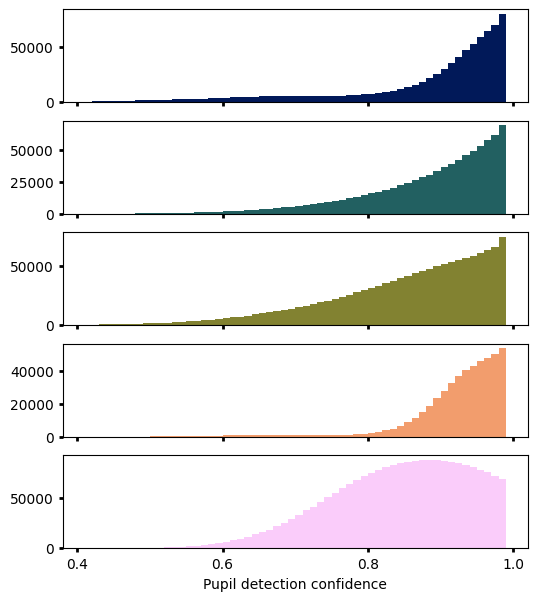

In [42]:
# Pupil detection confidence per frame plot
fig, axes = plt.subplots(5, 1, figsize=(6, 7), sharex=True)

subjects = layout_eyetrackprep.get_subject()

cmap=cm.batlow.resampled(len(subjects))
fd_per_frames = {}

for i, sub in enumerate(subjects):
    
    raw_data = df_gaze[df_gaze['subject']==f'sub-{sub}']['confidence']
    raw_data = np.array(raw_data[raw_data>0])

    axes[i].hist(raw_data.reshape(-1), bins=np.arange(0, 1, 0.01), color=cmap.colors[i])
    axes[i].tick_params(width=2, size=3)

plt.xlabel('Pupil detection confidence')
plt.xlim([0.38, 1.02])
plt.xticks([0.4, 0.6, 0.8, 1.0], ['0.4', '0.6', '0.8', '1.0'])

output_path.mkdir(parents=True, exist_ok=True)
plt.savefig(os.path.join(output_path, 'pupil_confidence_perFrame.svg'), dpi=600, bbox_inches='tight', transparent=True)

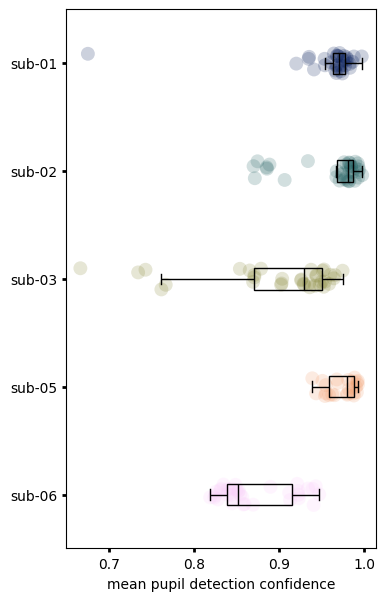

In [41]:
np.random.seed(42)

df_conf_run = pd.DataFrame()
for sub in df_gaze['subject'].unique():
    tmp_gaze = df_gaze[df_gaze['subject']==sub]
    for ses in tmp_gaze['session'].unique():
        tmp_gaze_ses = tmp_gaze[tmp_gaze['session']==ses]
        for run in tmp_gaze_ses['run'].unique():
            conf = tmp_gaze_ses[tmp_gaze_ses['run']==run]['confidence']
            mean_confidence = conf[conf>0].mean()
            df_conf_run = pd.concat([
                df_conf_run, 
                pd.DataFrame({'subject_id': [sub], 'session_id': [ses], 'run_id': [run], 'mean_pupil_confidence': [mean_confidence]})
            ])

f, ax = plt.subplots(figsize=(4, 7))
dy="subject_id"; dx="mean_pupil_confidence"; ort="h"; 
cmap=sns.color_palette(cm.batlow.resampled(len(subjects)).colors)

ax=sns.stripplot(x = dx, y = dy, data = df_conf_run, palette = cmap, edgecolor = "white",
                 size = 3, alpha=0.20, s=10, jitter = 0.1, zorder = 0, orient = ort)

ax=sns.boxplot(x = dx, y = dy, data = df_conf_run, color = "black", width = .20, zorder = 10, 
               showcaps = True, boxprops = {'facecolor':'none', "zorder":10},
               showfliers=False, whiskerprops = {'linewidth':1, "zorder":10},
               saturation = 1, orient = ort)

ax.tick_params(width=2, size=3)

plt.xlabel('mean pupil detection confidence')
plt.ylabel('')

output_path.mkdir(parents=True, exist_ok=True)
plt.savefig(os.path.join(output_path, 'pupil_confidence_perRun.svg'), dpi=600, bbox_inches='tight', transparent=True)